# Tree tensor training

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt

from tree_tensor.tree_tensor_torch import TreeBasedTensor
from tree_cross.tree_cross_torch import TreeCross
from pde.coeff_function import coeff
from benchmarks.util import RMS
from benchmarks.tree_tensor_training_explicit import ARGS_tree_tensor_training_explicit, tree_tensor_training_explicit

In [2]:
args = ARGS_tree_tensor_training_explicit(
  verbose = 1,
  Nx = 10,           # spatial resolution
  Ny = 5,            # parameter resolution
  Ny_decay = False,
  n_param = 5,       # number of parameters for diffusion coeff
  c_offset = 1,      # parameter mean
  c_var = 4,         # 'variance' of the parameters
  tree_type = 'balanced',
  N_train = int(1e5),
  N_test = int(1e3),
  optimizer = 'adam',
  lr_start = 1e-2,
  lr_end = 1e-6,
  rinit = 20,
  epoch_outer = 100,
  epoch_inner = 20,
  eps = 1e-4,
  N_mc = 500,
)

cfun_np = coeff(args.Nx, args.Ny, args.c_offset, args.c_var, args.c_decay)
cfun = lambda x : torch.from_numpy(cfun_np(x))

In [3]:
stats, tensor = tree_tensor_training_explicit(args, return_tensor=True)
tensor.tree.print()

Running tree tensor training (explicit gradients)...
ARGS_tree_tensor_training_explicit(verbose=1, Nx=10, Ny=5, Ny_decay=False, n_param=5, c_offset=1, c_var=4, c_decay=2.0, tree_type='balanced', tree_weight_decay=0.0, N_train=100000, N_test=1000, optimizer='adam', lr_start=0.01, lr_end=1e-06, rinit=20, epoch_outer=100, epoch_inner=20, eps=0.0001, rng_seed=0, N_mc=500, device='cpu')
epoch 0, train loss 3.36e+00, validation loss 3.31e+00, lr 1.0e-02, size 7325
epoch 1, train loss 2.52e-01, validation loss 2.49e-01, lr 1.0e-02, size 7325
epoch 2, train loss 2.76e-02, validation loss 2.71e-02, lr 1.0e-02, size 7325
epoch 3, train loss 1.86e-02, validation loss 1.82e-02, lr 1.0e-02, size 7325
epoch 4, train loss 1.71e-02, validation loss 1.65e-02, lr 1.0e-02, size 7325
epoch 5, train loss 1.92e-02, validation loss 1.87e-02, lr 1.0e-02, size 7325
epoch 6, train loss 1.85e-02, validation loss 1.75e-02, lr 1.0e-02, size 7325
epoch 7, train loss 1.84e-02, validation loss 1.80e-02, lr 1.0e-02, s

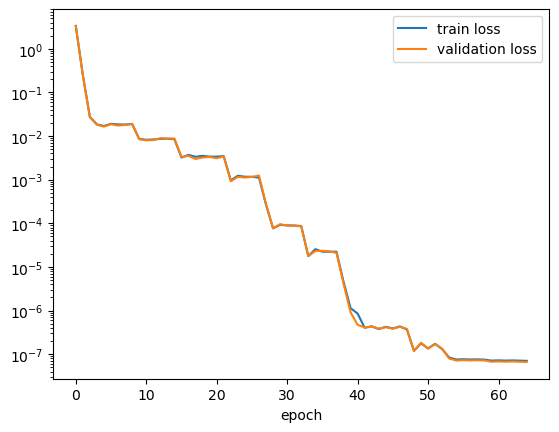

In [4]:
fig, ax = plt.subplots()
ax.plot(stats['train_loss'], label='train loss')
ax.plot(stats['test_loss'], label='validation loss')

ax.set_xlabel('epoch')
ax.set_yscale('log')
ax.legend()

## Comparison with cross approximation

In [5]:
rng = np.random.default_rng()

def err_MC(tensor, cfun, N_MC=500):
  errs = np.zeros(N_MC)
  for i in range(N_MC):
    # eval tree tensor approx of coeff at random parameter
    y = rng.integers(0, tensor.shape[1:])
    C_eval = torch.ravel(tensor[:, *y])

    X = np.hstack([np.arange(args.Nx).reshape((-1,1)), np.tile(y, [args.Nx,1])])
    C_true = cfun(X)

    errs[i] = RMS((C_eval-C_true).numpy(force=True))

  return errs

In [21]:
n_iter = 10
tol = 1e-4
kickrank = 0

C_a = TreeBasedTensor.randn(tensor.tree, tensor.shape, 10)
cross = TreeCross(C_a)

cross.run(cfun, n_iter=n_iter, eps=tol, kickrank=kickrank, random_kick=1, verbose=1)
C_a.round(tol=1e-4)

swp:  1/10 f_evals=1244 self.max_dx=2.72e+01
swp:  2/10 f_evals=2474 self.max_dx=1.21e+00
swp:  3/10 f_evals=3987 self.max_dx=2.90e-01
swp:  4/10 f_evals=5647 self.max_dx=2.39e-01
swp:  5/10 f_evals=7472 self.max_dx=3.14e-02
swp:  6/10 f_evals=9427 self.max_dx=1.78e-02
swp:  7/10 f_evals=11382 self.max_dx=4.74e-05


In [22]:
err_cross = err_MC(C_a, cfun, args.N_mc)
err_train = err_MC(tensor, cfun, args.N_mc)

print(f'cross approximation: error {RMS(err_cross):.2e}, size {C_a.sparse_size}')
print(f'training:            error {RMS(err_train):.2e}, size {tensor.sparse_size}')

cross approximation: error 2.49e-04, size 1350
training:            error 2.48e-04, size 1350
